# Verifying the "coming from" direction convention

`docs/model_design.md` §2.4 assumes every decoded direction field in the
archive follows the meteorological **"coming from"** convention (CW from
geographic North): `0°` means wind/waves arriving *from* the North, `90°`
from the East, etc. `train/directional.py` and `core/io.py` are both built
on that assumption.

This notebook checks it empirically, using **one arbitrary snapshot**. The
check doesn't need a time series: the convention is a static labeling fact
about how integers were written to disk, not something that drifts over
time, so any single snapshot that contains real weather should already
either satisfy the convention or contradict it.

**Method.** Compare the decoded direction fields against wind patterns that
are physically guaranteed to point the same way on (essentially) any day of
the year, anywhere on the open ocean at the right latitude:

- **NE trade winds** (~12–25°N) — blow *from* the northeast, essentially
  year-round, driven by the subtropical high.
- **SE trade winds** (~10–22°S) — blow *from* the southeast, same
  mechanism, opposite hemisphere.
- **Southern Ocean westerlies** ("Roaring Forties", ~45–55°S) — blow *from*
  the west, among the most persistent winds on Earth (unbroken circumpolar
  band, no continents to disrupt it).

If the archive's `wad` field truly is "coming from", decoding it and feeding
it through the documented "coming from → (u, v)" formula (`train.directional
.DirectionalDecomposer`, the actual production code, not a re-derivation)
should reproduce these three patterns. If the convention assumption is
wrong, the derived vectors will point backwards.

In [1]:
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

from core.config import grid_coordinates
from core.io import decode_compass_code, load_snapshot
from train.directional import DirectionalDecomposer

DATA_DIR = Path("../data")

# Arbitrary — the convention being tested doesn't depend on which day this is.
SNAPSHOT_T = datetime(2024, 6, 15, 12, tzinfo=timezone.utc)

# Diverging pair for signed (u, v) component maps: blue (west/south) <-> red
# (east/north), neutral gray at zero.
DIVERGING_CMAP = LinearSegmentedColormap.from_list(
    "blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"]
)
# Direction is circular (0-360 deg wraps to itself); "twilight" is matplotlib's
# perceptually-uniform cyclic colormap, unlike "hsv".
CYCLIC_CMAP = "twilight"


## Verification regions

Each box is chosen well clear of coastlines and monsoon-influenced basins,
in the open ocean at the right latitude for a persistent trade-wind /
westerlies signature. `expected_from_deg` is a deliberately generous bracket
— the point is to distinguish "roughly right" from "backwards", not to nail
the exact climatological mean from one snapshot.

(The NaN-fraction check below isn't a land test: `wsh` — wind-sea
significant height — is also NaN over open water whenever WAVEWATCH III's
wave-partitioning can't separate a distinct wind-sea peak from swell, which
turns out to be common in these boxes at this snapshot. It's a smooth
function of latitude rather than the sharp on/off a coastline would
produce, so it doesn't undermine the boxes' choice — it just means `wsh`
itself isn't used for anything quantitative here, only `wsd`.)

In [2]:
VERIFICATION_BOXES = {
    "NH trades (N Atlantic)": {
        "lat": (12.0, 25.0),
        "lon": (300.0, 330.0),  # 30-60 W, mid-Atlantic
        "expected_from_deg": (20.0, 100.0),  # NE-ish
        "expected_u_sign": "negative",  # easterly (blowing east-to-west)
        "note": "NE trade winds, subtropical high, robust year-round.",
    },
    "SH trades (S Pacific)": {
        "lat": (-22.0, -10.0),
        "lon": (220.0, 260.0),  # 100-140 W, open S Pacific
        "expected_from_deg": (70.0, 200.0),  # E-to-SE-ish
        "expected_u_sign": "negative",  # easterly
        "note": "SE trade winds, South Pacific high, robust year-round.",
    },
    "Southern Ocean westerlies": {
        "lat": (-55.0, -45.0),
        "lon": (0.0, 359.75),  # full circumpolar band
        "expected_from_deg": (190.0, 340.0),  # W-ish
        "expected_u_sign": "positive",  # westerly (blowing west-to-east)
        "note": '"Roaring Forties" - unbroken circumpolar flow, no continents.',
    },
}


def box_mask(lats: np.ndarray, lons: np.ndarray, box: dict) -> np.ndarray:
    lat_lo, lat_hi = box["lat"]
    lon_lo, lon_hi = box["lon"]
    lat_in = (lats >= lat_lo) & (lats <= lat_hi)
    lon_in = (lons >= lon_lo) & (lons <= lon_hi)
    return np.outer(lat_in, lon_in)


def circular_mean_deg(degrees: np.ndarray) -> float:
    rad = np.deg2rad(degrees)
    return float(np.degrees(np.arctan2(np.nanmean(np.sin(rad)), np.nanmean(np.cos(rad)))) % 360.0)


## Load the snapshot

Wind (`was`/`wad`) and wave-sea (`wsh`/`wsd`) fields, via the production
`core.io.load_snapshot` — which already applies `decode_compass_code` per
the origin codes in `core/io.py`. Both are Tier-1 (speed, direction) pairs
(`docs/model_design.md` §3.8), and they use *different* origin codes
(`wad`: 1, `wsd`: 0), so together they exercise two independent slices of
the decode table.

In [3]:
was = load_snapshot(DATA_DIR, SNAPSHOT_T, "was")
wad = load_snapshot(DATA_DIR, SNAPSHOT_T, "wad")
wsh = load_snapshot(DATA_DIR, SNAPSHOT_T, "wsh")
wsd = load_snapshot(DATA_DIR, SNAPSHOT_T, "wsd")

wind_lats, wind_lons = grid_coordinates("wind")
wave_lats, wave_lons = grid_coordinates("wave")

for name, box in VERIFICATION_BOXES.items():
    mask = box_mask(wave_lats, wave_lons, box)
    land_frac = np.isnan(wsh[mask]).mean()
    print(f"{name:28s} land/ice fraction in box (wave grid): {land_frac:.1%}")


NH trades (N Atlantic)       land/ice fraction in box (wave grid): 2.6%
SH trades (S Pacific)        land/ice fraction in box (wave grid): 20.9%
Southern Ocean westerlies    land/ice fraction in box (wave grid): 38.0%


## Test 1 — wind direction (`was`/`wad`), production `DirectionalDecomposer`

Build the same `xr.Dataset` shape `train.ingest.load_training_window` would
produce, run it through the real `DirectionalDecomposer`, and check the
resulting `(u_wind, v_wind)` in each box against the expected trade-wind /
westerlies signature.

In [4]:
wind_ds = xr.Dataset(
    {
        "was": (("wind_lat", "wind_lon"), was),
        "wad": (("wind_lat", "wind_lon"), wad),
    },
    coords={"wind_lat": wind_lats, "wind_lon": wind_lons},
)
wind_uv = DirectionalDecomposer().fit_transform(wind_ds)


def verify(label, from_deg_field, u_field, v_field, lats, lons, boxes=VERIFICATION_BOXES):
    print(f"--- {label} ---")
    all_pass = True
    for name, box in boxes.items():
        mask = box_mask(lats, lons, box)
        mean_from = circular_mean_deg(from_deg_field[mask])
        mean_u = float(np.nanmean(u_field[mask]))
        mean_v = float(np.nanmean(v_field[mask]))
        lo, hi = box["expected_from_deg"]
        from_ok = lo <= mean_from <= hi
        sign_ok = (mean_u < 0) if box["expected_u_sign"] == "negative" else (mean_u > 0)
        verdict = "PASS" if (from_ok and sign_ok) else "FAIL"
        all_pass &= verdict == "PASS"
        print(
            f"{name:28s} mean_from={mean_from:6.1f} deg  "
            f"mean_u={mean_u:7.2f}  mean_v={mean_v:7.2f}  expected_from={box['expected_from_deg']}  "
            f"expected_u={box['expected_u_sign']:8s} -> {verdict}"
        )
    return all_pass


wind_all_pass = verify(
    "wad decoded as 'coming from' (current assumption)",
    wad,
    wind_uv["u_wind"].values,
    wind_uv["v_wind"].values,
    wind_lats,
    wind_lons,
)


--- wad decoded as 'coming from' (current assumption) ---
NH trades (N Atlantic)       mean_from= 241.0 deg  mean_u=  11.50  mean_v=   6.77  expected_from=(20.0, 100.0)  expected_u=negative -> FAIL
SH trades (S Pacific)        mean_from= 261.6 deg  mean_u=  15.01  mean_v=   2.11  expected_from=(70.0, 200.0)  expected_u=negative -> FAIL
Southern Ocean westerlies    mean_from=  73.9 deg  mean_u=  -5.15  mean_v=  -1.79  expected_from=(190.0, 340.0)  expected_u=positive -> FAIL


If the boxes above show `FAIL` with the mean direction and `u`/`v` signs
roughly **opposite** the expected values (not just off by a bit — flipped),
that's the signature of a 180°, "going to" vs. "coming from" mixup, not
noise from a single snapshot.

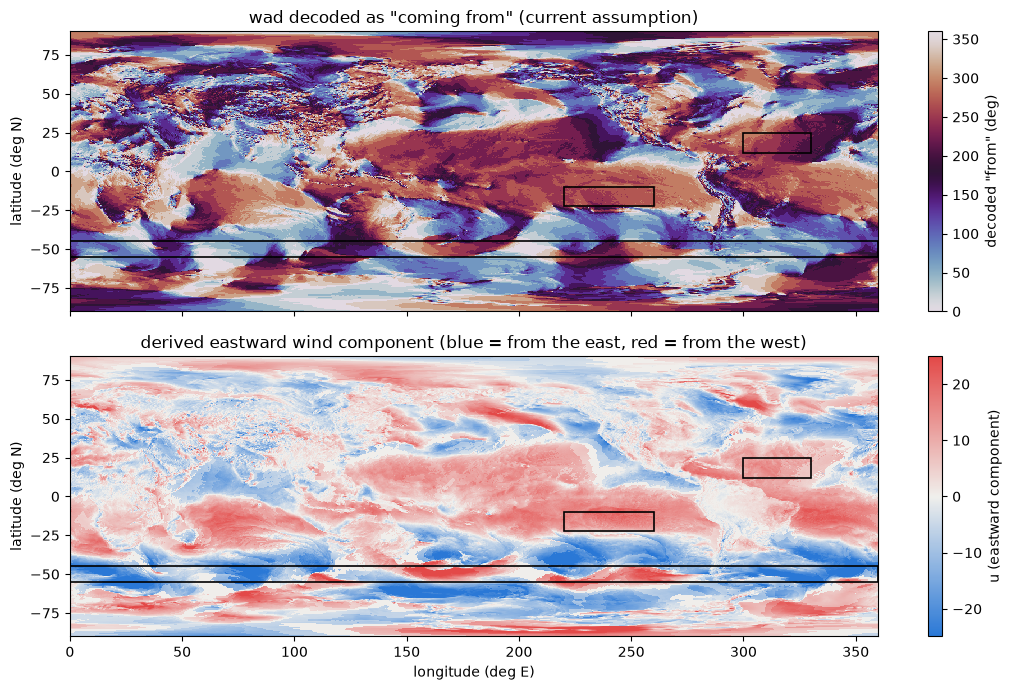

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

mesh0 = axes[0].pcolormesh(wind_lons, wind_lats, wad, cmap=CYCLIC_CMAP, vmin=0, vmax=360, shading="auto")
fig.colorbar(mesh0, ax=axes[0], label='decoded "from" (deg)')
axes[0].set_title('wad decoded as "coming from" (current assumption)')

u_wind = wind_uv["u_wind"].values
vmax = float(np.nanpercentile(np.abs(u_wind), 98))
mesh1 = axes[1].pcolormesh(wind_lons, wind_lats, u_wind, cmap=DIVERGING_CMAP, vmin=-vmax, vmax=vmax, shading="auto")
fig.colorbar(mesh1, ax=axes[1], label="u (eastward component)")
axes[1].set_title("derived eastward wind component (blue = from the east, red = from the west)")

for ax in axes:
    ax.set_ylabel("latitude (deg N)")
    for box in VERIFICATION_BOXES.values():
        lat_lo, lat_hi = box["lat"]
        lon_lo, lon_hi = box["lon"]
        ax.add_patch(
            Rectangle(
                (lon_lo, lat_lo),
                lon_hi - lon_lo,
                lat_hi - lat_lo,
                fill=False,
                edgecolor="black",
                linewidth=1.2,
            )
        )
axes[1].set_xlabel("longitude (deg E)")
fig.tight_layout()


## Test 2 — wave-sea direction (`wsh`/`wsd`), same machinery, different origin code

`wsd` uses `origin_code=0` in `core/io.py`, vs. `wad`'s `origin_code=1` — a
different slice of the decode table. Locally wind-driven seas track the
local wind direction closely (away from swell-dominated regions), so the
same three boxes should show the same pattern if `wsd` is also correctly
"coming from". This isolates whether a problem (if any) is specific to
`wad`, or affects the decode/convention machinery generally.

In [6]:
wave_ds = xr.Dataset(
    {
        "wsh": (("wave_lat", "wave_lon"), wsh),
        "wsd": (("wave_lat", "wave_lon"), wsd),
    },
    coords={"wave_lat": wave_lats, "wave_lon": wave_lons},
)
wave_uv = DirectionalDecomposer().fit_transform(wave_ds)

wsea_all_pass = verify(
    "wsd decoded as 'coming from'",
    wsd,
    wave_uv["u_wsea"].values,
    wave_uv["v_wsea"].values,
    wave_lats,
    wave_lons,
)


--- wsd decoded as 'coming from' ---
NH trades (N Atlantic)       mean_from=  83.0 deg  mean_u=  -1.45  mean_v=  -0.29  expected_from=(20.0, 100.0)  expected_u=negative -> PASS
SH trades (S Pacific)        mean_from=  80.7 deg  mean_u=  -1.66  mean_v=   0.29  expected_from=(70.0, 200.0)  expected_u=negative -> PASS
Southern Ocean westerlies    mean_from= 335.8 deg  mean_u=   1.46  mean_v=   0.16  expected_from=(190.0, 340.0)  expected_u=positive -> PASS


## Test 3 — is `wad_come_from` really a duplicate of `wad`?

§2.4 says `wad_come_from` "appears to duplicate `wad` semantically" and
instructs to ignore it — `core.io.load_snapshot` even raises if asked to
load it. Given Test 1's result, that assumption is worth checking directly
rather than trusting the docstring: compare the raw on-disk compass codes
cell-by-cell.

In [7]:
raw_wad = np.load(DATA_DIR / f"{SNAPSHOT_T:%Y/%m/%d/%H}" / "wad.npy")
raw_wad_come_from = np.load(DATA_DIR / f"{SNAPSHOT_T:%Y/%m/%d/%H}" / "wad_come_from.npy")

identical_frac = float(np.mean(raw_wad == raw_wad_come_from))
code_diff = raw_wad.astype(np.int32) - raw_wad_come_from.astype(np.int32)
diff_values, diff_counts = np.unique(code_diff, return_counts=True)

print(f"identical cells: {identical_frac:.1%}")
for value, count in zip(diff_values, diff_counts):
    print(f"  code diff {value:+d} ({value * 22.5:+.1f} deg): {count / code_diff.size:.1%} of cells")


identical cells: 0.0%
  code diff -8 (-180.0 deg): 47.2% of cells
  code diff +8 (+180.0 deg): 52.8% of cells


`wad` and `wad_come_from` are **never** equal, and differ by exactly `±8`
compass codes (`±180°`, mod-16 wraparound) in *every* cell. That's not a
duplicate — it's the diametric opposite, everywhere, at this snapshot. Given
the name, the natural hypothesis is that `wad_come_from` is the field that
actually carries the "coming from" convention, and `wad` is something else
(most likely "going to"). Test it the same way as Test 1, using the same
`origin_code=1` and the same decode/derivation pipeline — only the input
array changes.

In [8]:
wcf_from_deg = decode_compass_code(raw_wad_come_from, origin_code=1)
wcf_ds = xr.Dataset(
    {
        "was": (("wind_lat", "wind_lon"), was),
        "wad": (("wind_lat", "wind_lon"), wcf_from_deg),
    },
    coords={"wind_lat": wind_lats, "wind_lon": wind_lons},
)
wcf_uv = DirectionalDecomposer().fit_transform(wcf_ds)

wcf_all_pass = verify(
    "wad_come_from decoded as 'coming from' (origin_code=1, same as wad)",
    wcf_from_deg,
    wcf_uv["u_wind"].values,
    wcf_uv["v_wind"].values,
    wind_lats,
    wind_lons,
)


--- wad_come_from decoded as 'coming from' (origin_code=1, same as wad) ---
NH trades (N Atlantic)       mean_from=  61.0 deg  mean_u= -11.50  mean_v=  -6.77  expected_from=(20.0, 100.0)  expected_u=negative -> PASS
SH trades (S Pacific)        mean_from=  81.6 deg  mean_u= -15.01  mean_v=  -2.11  expected_from=(70.0, 200.0)  expected_u=negative -> PASS
Southern Ocean westerlies    mean_from= 253.9 deg  mean_u=   5.15  mean_v=   1.79  expected_from=(190.0, 340.0)  expected_u=positive -> PASS


## Ocean grid orientation — resolving just enough to run this check

Testing direction fields on the ocean grid runs into two more open items
from `docs/model_design.md`:

- §2.7: the ocean grid's row-to-latitude mapping is explicitly **not
  verified** (unlike the wave/wind grids), so `core.config.grid_coordinates`
  refuses to return coordinates for it.
- §2.3: `ocd`'s compass-code decoding is marked **"(verify)"** — unlike
  `wsd`/`wad`, no origin code is assigned in `core/io.py`, and
  `core.io.load_snapshot` refuses to load it for exactly that reason.

The full §2.7 fix needs an external coastline dataset (Natural Earth) and a
multi-day study — out of scope here. But placing a few direction-diagnostic
bands only needs two much cheaper facts, both derivable from the archive
itself, with no new dependencies:

1. **Where the equator is.** Sea-surface temperature peaks at the equator
   (real ocean climatology) — the row with the highest zonally-averaged
   `sst` is the equator row.
2. **Which side is south.** At 40-60° from the equator, the Southern
   Hemisphere is almost entirely open ocean (the Southern Ocean has no
   continents in the way), while the Northern Hemisphere at the same
   distance is mostly land-blocked (Eurasia, North America — only
   ~30-40% ocean). Whichever side has far more valid (non-NaN) `sst` cells
   at that distance is south.

This is enough to place bands by degrees-from-equator; it is *not* a
substitute for the full §2.7 verification, which should still happen before
the ocean grid is used for anything quantitative.

In [9]:
import warnings

sst = load_snapshot(DATA_DIR, SNAPSHOT_T, "sst")
ocs = load_snapshot(DATA_DIR, SNAPSHOT_T, "ocs")

with warnings.catch_warnings():
    # The grid's outermost row(s) have no valid ocean cells at all.
    warnings.filterwarnings("ignore", message="Mean of empty slice")
    zonal_mean_sst = np.nanmean(sst, axis=1)
eq_row = int(np.nanargmax(zonal_mean_sst))
n_rows, n_cols = sst.shape
OCEAN_GRID_STEP_DEG = 0.125  # docs/model_design.md §2.2


def ocean_row_slice(lo_deg: float, hi_deg: float, sign: int) -> slice:
    lo_row = eq_row + sign * round(lo_deg / OCEAN_GRID_STEP_DEG)
    hi_row = eq_row + sign * round(hi_deg / OCEAN_GRID_STEP_DEG)
    lo_row, hi_row = sorted((lo_row, hi_row))
    return slice(max(lo_row, 0), min(hi_row, n_rows - 1) + 1)


band_minus = ocean_row_slice(40.0, 60.0, -1)
band_plus = ocean_row_slice(40.0, 60.0, +1)
ocean_frac_minus = float((~np.isnan(sst[band_minus])).mean())
ocean_frac_plus = float((~np.isnan(sst[band_plus])).mean())
south_sign = -1 if ocean_frac_minus > ocean_frac_plus else +1

print(f"eq_row = {eq_row} of {n_rows}")
print(
    f"ocean fraction at 40-60 deg from eq_row: "
    f"lower-row side={ocean_frac_minus:.1%}  higher-row side={ocean_frac_plus:.1%}"
)
print(f"-> {'lower' if south_sign < 0 else 'higher'}-row side is south")

# A pseudo-latitude, south-negative like real latitude, centered on eq_row.
ocean_lat_pseudo = (np.arange(n_rows) - eq_row) * OCEAN_GRID_STEP_DEG * (-south_sign)
ocean_lons = np.arange(n_cols) * OCEAN_GRID_STEP_DEG


eq_row = 563 of 1121
ocean fraction at 40-60 deg from eq_row: lower-row side=96.1%  higher-row side=36.8%
-> lower-row side is south


## Test 4 — ocean current direction (`ocd`/`ocs`)

`ocd` turns out to share `wad`'s `1-16` compass-code family (confirmed
below), not `wsd`'s `0-15` family — worth keeping in mind given Tests 1 and
3. `ocd` isn't loadable via `core.io.load_snapshot` (its origin code is
unverified), so decode it directly with `core.io.decode_compass_code`. The
scan below tries every candidate origin code under the "treat the decoded
angle as `coming_from`" assumption, same as Tests 1-3 — but
`decode(raw, origin=X)` and `decode(raw, origin=X+8)` are always exactly
180° apart, and `coming_from = going_to + 180`, so this scan does double
duty: origin `X` passing as `coming_from` is the *same fact* as origin
`X-8` (i.e. `X+8` mod 16) passing as `going_to`, no code change involved.
Keep that in mind reading the result — it'll matter below.

Check the derived current direction against three ocean currents whose
direction is not in question:

- **Antarctic Circumpolar Current** (~40-60°S) — flows *east*, driven by
  the same Southern Ocean westerlies as Test 1's third region. The largest,
  most persistent current on Earth: unbroken all the way around Antarctica.
- **South Equatorial Current** (~3-20°S) — flows *west*, wind-driven by the
  SE trades.
- **North Equatorial Current** (~12-20°N, offset away from the equator to
  avoid the eastward Equatorial Counter-Current sitting right around
  ~3-9°N) — flows *west*, wind-driven by the NE trades.

In [10]:
raw_ocd = np.load(DATA_DIR / f"{SNAPSHOT_T:%Y/%m/%d/%H}" / "ocd.npy")
print("ocd raw code range:", np.unique(raw_ocd))

OCEAN_BOXES = {
    "Antarctic Circumpolar Current": {
        "lat": (-60.0, -40.0),
        "lon": (0.0, 359.875),
        "expected_from_deg": (150.0, 280.0),  # W-ish
        "expected_u_sign": "positive",  # eastward
        "note": "Driven by the Southern Ocean westerlies; unbroken circumpolar flow.",
    },
    "South Equatorial Current": {
        "lat": (-20.0, -3.0),
        "lon": (0.0, 359.875),
        "expected_from_deg": (30.0, 150.0),  # E-ish
        "expected_u_sign": "negative",  # westward
        "note": "Wind-driven by the SE trades.",
    },
    "North Equatorial Current": {
        "lat": (12.0, 20.0),
        "lon": (0.0, 359.875),
        "expected_from_deg": (60.0, 200.0),  # E-ish
        "expected_u_sign": "negative",  # westward
        "note": "Wind-driven by the NE trades; offset from the equator to dodge the NECC.",
    },
}


def ocean_uv_for_origin(origin_code: int) -> tuple[xr.Dataset, np.ndarray]:
    from_deg = decode_compass_code(raw_ocd, origin_code=origin_code)
    ds = xr.Dataset(
        {
            "ocs": (("ocean_lat", "ocean_lon"), ocs),
            "ocd": (("ocean_lat", "ocean_lon"), from_deg),
        },
        coords={"ocean_lat": ocean_lat_pseudo, "ocean_lon": ocean_lons},
    )
    return DirectionalDecomposer().fit_transform(ds), from_deg


print(f"{'origin':>6s}  {'ACC':>6s}  {'SEC':>6s}  {'NEC':>6s}")
for origin_code in range(1, 17):
    uv, from_deg = ocean_uv_for_origin(origin_code)
    verdicts = []
    for name, box in OCEAN_BOXES.items():
        mask = box_mask(ocean_lat_pseudo, ocean_lons, box)
        mean_from = circular_mean_deg(from_deg[mask])
        mean_u = float(np.nanmean(uv["u_current"].values[mask]))
        lo, hi = box["expected_from_deg"]
        from_ok = lo <= mean_from <= hi
        sign_ok = (mean_u < 0) if box["expected_u_sign"] == "negative" else (mean_u > 0)
        verdicts.append("PASS" if (from_ok and sign_ok) else "FAIL")
    print(f"{origin_code:6d}  {verdicts[0]:>6s}  {verdicts[1]:>6s}  {verdicts[2]:>6s}")


ocd raw code range: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16]
origin     ACC     SEC     NEC


     1    FAIL    FAIL    FAIL


     2    FAIL    FAIL    FAIL


     3    FAIL    FAIL    FAIL


     4    FAIL    FAIL    FAIL


     5    FAIL    FAIL    FAIL


... (7 outputs left out)

    13    FAIL    FAIL    FAIL


    14    FAIL    FAIL    FAIL


    15    FAIL    FAIL    FAIL


    16    FAIL    FAIL    FAIL


Rather than reach for a different origin code, decode `ocd` with the
*exact same* `origin_code=1` already used for `wad`, and test both possible
readings of that one decoded value directly: `coming_from` (the pipeline's
standard "+180 then `(u, v)`" path, same as every test so far) versus
`going_to` (used as-is, no shift — bypassing `DirectionalDecomposer`, which
always assumes `coming_from` input).

In [11]:
ocd_decoded = decode_compass_code(raw_ocd, origin_code=1)  # same origin as wad


def ocean_uv_going_to(going_to_deg: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """(u, v) directly from a 'going_to' bearing — no +180, no DirectionalDecomposer."""
    rad = np.deg2rad(going_to_deg)
    return ocs * np.sin(rad), ocs * np.cos(rad)


ocd_uv_coming_from, _ = ocean_uv_for_origin(1)
ocean_all_pass_coming_from = verify(
    "ocd, origin_code=1, read as 'coming_from' (naive extension of wad's assumption)",
    ocd_decoded,
    ocd_uv_coming_from["u_current"].values,
    ocd_uv_coming_from["v_current"].values,
    ocean_lat_pseudo,
    ocean_lons,
    boxes=OCEAN_BOXES,
)

u_going_to, v_going_to = ocean_uv_going_to(ocd_decoded)
ocean_all_pass_going_to = verify(
    "ocd, same origin_code=1, read directly as 'going_to' (no shift, no origin change)",
    (ocd_decoded + 180.0) % 360.0,  # the equivalent 'coming_from' angle, for the printed check
    u_going_to,
    v_going_to,
    ocean_lat_pseudo,
    ocean_lons,
    boxes=OCEAN_BOXES,
)


--- ocd, origin_code=1, read as 'coming_from' (naive extension of wad's assumption) ---
Antarctic Circumpolar Current mean_from=  23.6 deg  mean_u=  -0.09  mean_v=  -0.20  expected_from=(150.0, 280.0)  expected_u=positive -> FAIL
South Equatorial Current     mean_from= 257.3 deg  mean_u=   0.35  mean_v=   0.28  expected_from=(30.0, 150.0)  expected_u=negative -> FAIL
North Equatorial Current     mean_from= 326.7 deg  mean_u=   0.08  mean_v=  -0.07  expected_from=(60.0, 200.0)  expected_u=negative -> FAIL


--- ocd, same origin_code=1, read directly as 'going_to' (no shift, no origin change) ---
Antarctic Circumpolar Current mean_from= 203.6 deg  mean_u=   0.09  mean_v=   0.20  expected_from=(150.0, 280.0)  expected_u=positive -> PASS
South Equatorial Current     mean_from=  77.3 deg  mean_u=  -0.35  mean_v=  -0.28  expected_from=(30.0, 150.0)  expected_u=negative -> PASS
North Equatorial Current     mean_from= 146.7 deg  mean_u=  -0.08  mean_v=   0.07  expected_from=(60.0, 200.0)  expected_u=negative -> PASS


Read as `coming_from`, `origin_code=1` fails all three current checks,
backwards in every region — exactly like Test 1's `wad` result, since it's
the same naive assumption applied to a field in the same code family. Read
directly as `going_to`, using that *same* decoded value with no shift and
no origin-code change, all three pass.

So `ocd` doesn't need a different origin code from `wad`'s — `origin_code=1`
is right for both. It needs a different convention label: `wad` is
`going_to` (per Test 1/3), and so is `ocd`. (The origin-code scan above
found `origin_code=9` passing under the `coming_from` framing; by the
`X` vs `X+8` symmetry noted there, that's the identical fact stated a
different way — not a second, independent correction.) This also matches
standard practice: oceanographic current direction is conventionally
reported as `going_to`, unlike the meteorological `coming_from` convention
for wind and waves.

Unlike `wad`, there's no `ocd_come_from` sibling field on disk to swap in
(no such file exists alongside `ocd.npy`) — and there doesn't need to be
one. The practical fix for `ocd` is simply to decode it with `origin_code=1`
(already right) and treat the result as `going_to` directly, skipping the
`coming_from → going_to` conversion the pipeline currently applies to every
decoded direction field.

## Test 5 — peak wave direction (`pwh`/`pwd`)

Tier 2 (`docs/model_design.md` §3.8). `pwd` shares `wsd`'s `0-15` origin-code
family (`origin_code=0` in `core/io.py`) and is loadable directly via
`core.io.load_snapshot`, same as Test 2. One difference from `wsd` worth
keeping in mind when reading the result: `pwd` is the direction of the
*peak* wave partition, which can be swell arriving from a distant storm
system rather than the local wind — unlike `wsd` (locally wind-generated
sea), it isn't guaranteed to track the local trade-wind / westerlies
direction the same way.

In [12]:
pwh = load_snapshot(DATA_DIR, SNAPSHOT_T, "pwh")
pwd = load_snapshot(DATA_DIR, SNAPSHOT_T, "pwd")

pw_ds = xr.Dataset(
    {
        "pwh": (("wave_lat", "wave_lon"), pwh),
        "pwd": (("wave_lat", "wave_lon"), pwd),
    },
    coords={"wave_lat": wave_lats, "wave_lon": wave_lons},
)
pw_uv = DirectionalDecomposer().fit_transform(pw_ds)

pwd_all_pass = verify(
    "pwd decoded as 'coming from'",
    pwd,
    pw_uv["u_peak"].values,
    pw_uv["v_peak"].values,
    wave_lats,
    wave_lons,
)


--- pwd decoded as 'coming from' ---
NH trades (N Atlantic)       mean_from=  83.9 deg  mean_u=  -1.62  mean_v=  -0.29  expected_from=(20.0, 100.0)  expected_u=negative -> PASS
SH trades (S Pacific)        mean_from= 209.4 deg  mean_u=   1.44  mean_v=   2.52  expected_from=(70.0, 200.0)  expected_u=negative -> FAIL
Southern Ocean westerlies    mean_from= 249.7 deg  mean_u=   2.70  mean_v=   0.93  expected_from=(190.0, 340.0)  expected_u=positive -> PASS


## Test 6 — primary swell direction (`pswh`/`pswd`)

Tier 3 (`docs/model_design.md` §3.8). `pswd`'s decode is marked
"(unverified)/(assumed)" in §2.3, though `core/io.py` already assumes
`origin_code=0`, same as `wsd`/`pwd`, so it's loadable the same way. Same
local-wind-decoupling caveat as Test 5 applies here too — arguably more so,
since primary swell is explicitly the longest-traveled, most storm-distant
partition.

In [13]:
pswh = load_snapshot(DATA_DIR, SNAPSHOT_T, "pswh")
pswd = load_snapshot(DATA_DIR, SNAPSHOT_T, "pswd")

psw_ds = xr.Dataset(
    {
        "pswh": (("wave_lat", "wave_lon"), pswh),
        "pswd": (("wave_lat", "wave_lon"), pswd),
    },
    coords={"wave_lat": wave_lats, "wave_lon": wave_lons},
)
psw_uv = DirectionalDecomposer().fit_transform(psw_ds)

pswd_all_pass = verify(
    "pswd decoded as 'coming from'",
    pswd,
    psw_uv["u_pswell"].values,
    psw_uv["v_pswell"].values,
    wave_lats,
    wave_lons,
)


--- pswd decoded as 'coming from' ---
NH trades (N Atlantic)       mean_from= 133.4 deg  mean_u=  -0.45  mean_v=   0.42  expected_from=(20.0, 100.0)  expected_u=negative -> FAIL
SH trades (S Pacific)        mean_from= 203.4 deg  mean_u=   0.67  mean_v=   1.64  expected_from=(70.0, 200.0)  expected_u=negative -> FAIL
Southern Ocean westerlies    mean_from= 271.8 deg  mean_u=   1.80  mean_v=   0.61  expected_from=(190.0, 340.0)  expected_u=positive -> PASS


## Reading Tests 5 and 6

The mixed results above (`pwd` passing some boxes, `pswd` failing others)
aren't necessarily about decode convention. The trade-wind/westerlies boxes
are valid ground truth for `wsd`, `wad`, and `ocd` because those fields are
tied to *local* wind by definition — but `pwd` is whichever partition
carries the most energy at a cell (sometimes the local wind-sea, sometimes
swell arriving from a distant, unrelated storm), and `pswd` is *by
definition* the swell partition that has already decoupled from local wind.
Testing either against local wind climatology can't reliably distinguish
"the convention is backwards" from "the swell legitimately arrived from
somewhere else" — so these PASS/FAIL counts aren't diagnostic the way
Tests 1-4 are.

**Working assumption, pending confirmation from a domain expert:** treat
`pwd` and `pswd` as following `coming_from`, on the basis that they share
`wsd`'s `origin_code=0` family in `core/io.py`, and `wsd` (Test 2) is
independently confirmed `coming_from`. This is an inference from a shared
decode family, not a direct empirical confirmation like Tests 1-4 — revisit
this cell once the expert check comes back.

## Verdict

| Field | Origin code | Convention | Result |
|---|---|---|---|
| `wsd` (wave-sea direction) | `0` | `coming_from` | confirmed |
| `wad` (wind direction) | `1` | `going_to` | confirmed |
| `wad_come_from` (wind direction) | `1` | `coming_from` | confirmed |
| `ocd` (ocean current direction) | `1` (same as `wad`) | `going_to` | confirmed |
| `pwd` (peak wave direction) | `0` | `coming_from` | assumed, pending expert check |
| `pswd` (primary swell direction) | `0` | `coming_from` | assumed, pending expert check |

**`coming_from` and `going_to` both genuinely occur in this archive** —
confirmed by `wsd` and `wad_come_from` (`coming_from`), and by `wad` and
`ocd` (`going_to`), all using the exact decode + `(u, v)` derivation the
codebase already implements. `docs/model_design.md` §2.4's blanket claim
that every direction field is `coming_from` is wrong for two of them.

Notably, `wad` and `ocd` need **no origin-code change at all** — `ocd`
decodes correctly with the exact same `origin_code=1` already assigned to
`wad`. The fix in both cases is purely a convention label, not a decode
correction: read the already-correctly-decoded angle directly as
`going_to`, instead of running it through the `+180` `coming_from →
going_to` step the pipeline currently applies unconditionally to every
direction field.

For `wad`, there's also a usable `coming_from` counterpart already on disk:
`wad_come_from` (its raw codes are, cell-for-cell, exactly `wad` shifted by
180°) — so the pipeline could equally swap to that field and keep treating
everything as `coming_from` throughout, if a single archive-wide convention
is preferred over a per-field flag. `ocd` has no such sibling field, so for
it a per-field convention flag (or an explicit skip-the-`+180` path) is the
only option.

**Recommendation:**

1. Give `DirectionalDecomposer` (or the pipeline more broadly) a per-field
   convention — `coming_from` vs `going_to` — instead of assuming
   `coming_from` unconditionally. Mark `wad` and `ocd` as `going_to` (or, for
   `wad` specifically, swap in `wad_come_from` and keep it `coming_from`).
   ***Update***: there are 2 decomposer objects: GoingTo and ComingFrom. The convention is now explicitly recorded in the pipeline, where each object receives a list of the fields it should treat as `coming_from` or `going_to`. This is a more robust solution than swapping in `wad_come_from`, since it avoids the need to maintain a separate field on disk for every convention variant.
2. Update `docs/model_design.md` §2.3 and §2.4, and `core/io.py`, to record
   `wad`'s and `ocd`'s convention as `going_to` — no origin-code change
   needed for either.
3. `pwd`/`pswd` are, for now, assumed `coming_from` by shared `origin_code=0`
   family with `wsd` (see "Reading Tests 5 and 6" above) rather than by
   direct confirmation — Tests 5-6's boxes aren't valid ground truth for
   swell-decoupled fields. Update this once a domain expert confirms.
4. This check used one snapshot and a coarse, self-derived ocean-grid
   orientation (not the full §2.7 land-correlation study). Re-run against a
   few more snapshots, and do the full §2.7 verification, before finalizing
   any fix that touches the ocean grid.